# =========================================================
# 2) INDICATORS
# Strategy (as specified):
# - Trend filter: SMMA(50) on CLOSE, compare CLOSE(shift=1) vs SMMA(50, shift=1)
# - KC: KC(20, dev=0.5) shift=1, compare OPEN(t) vs upper/lower
# - RSI: RSI(50) on CLOSE, slope:
#     Long:  RSI(shift=3) < RSI(shift=2)  (RSI increasing)
#     Short: RSI(shift=3) > RSI(shift=2)  (RSI decreasing)
# - Entry: STOP at
#     Long: Highest(HIGH, 30, shift=3)   (NO ATR buffer)
#     Short: Lowest(LOW,  30, shift=3)
#   Pending expiration = 8 bars
# - SL: 2.6 * ATR(20, shift=1)
# - TP: 3.6 * ATR(30, shift=1)
# - ExitAfterBars = 2
# - No trailing
# =========================================================

⏳ Downloading ETHUSDT 4h...
✅ Data ready: 4522 bars after indicator warmup.
🚀 Running backtest...

🎯 SMMA50(Close,s1) + KC(20,0.5,s1; Open) + RSI50 slope(3vs2) + STOP(HH/LL High/Low30,s3) + SL ATR20 + TP ATR30 + Exp8 + EAB2
  Final Equity: 13152.740863
  Total Return: 0.315274
 CAGR (approx): 0.142168
  Max Drawdown: -0.049727
        Sharpe: 2.030887
        Trades: 302
       Winrate: 0.496689
 Profit Factor: 1.508581


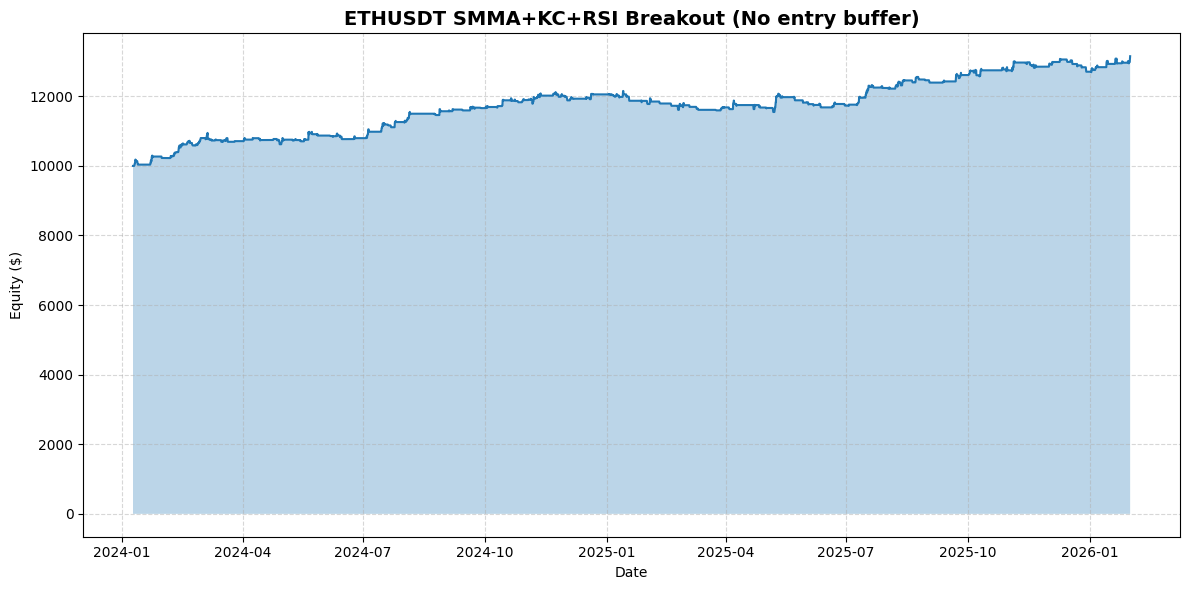


📊 Trades (first 12):
         Entry Time           Exit Time  Type   Entry        Exit  Qty          SL          TP         PnL        Reason      Balance
2024-01-10 04:00:00 2024-01-10 12:00:00  LONG 2361.50 2449.300000 0.87 2247.214426 2512.860307   76.386000 ExitAfterBars 10076.386000
2024-01-10 20:00:00 2024-01-11 04:00:00  LONG 2477.90 2589.150000 0.79 2350.626743 2642.230486   87.887500 ExitAfterBars 10164.273500
2024-01-11 12:00:00 2024-01-11 20:00:00  LONG 2657.89 2618.010000 0.66 2504.549895 2848.668128  -26.320800 ExitAfterBars 10137.952700
2024-01-12 12:00:00 2024-01-12 20:00:00  LONG 2689.39 2531.808252 0.64 2531.808252 2887.059123 -100.852319     Stop Loss 10037.100381
2024-01-22 08:00:00 2024-01-22 16:00:00 SHORT 2415.20 2321.870000 1.28 2493.022713 2293.257074  119.462400 ExitAfterBars 10156.562781
2024-01-23 00:00:00 2024-01-23 08:00:00 SHORT 2314.19 2218.140000 1.11 2405.274678 2181.615004  106.615500 ExitAfterBars 10263.178281
2024-01-23 16:00:00 2024-01-24 00:00:00 

In [4]:
import requests
import pandas as pd
import numpy as np
from datetime import datetime
import time
import matplotlib.pyplot as plt
import matplotlib.dates as mdates


# =========================================================
# 1) FETCH BINANCE DATA
# =========================================================
def str_to_millis(date_str: str) -> int:
    dt = datetime.strptime(date_str, "%d/%m/%Y")
    return int(dt.timestamp() * 1000)

def fetch_binance_kline_df(symbol: str, interval: str, start_str: str, end_str: str) -> pd.DataFrame:
    base_url = "https://api.binance.com/"
    url = base_url + "api/v3/klines"

    start_time = str_to_millis(start_str)
    end_dt = datetime.strptime(end_str, "%d/%m/%Y").replace(hour=23, minute=59, second=59)
    end_time = int(end_dt.timestamp() * 1000)

    all_klines = []
    print(f"⏳ Downloading {symbol} {interval}...")

    while start_time < end_time:
        params = {
            "symbol": symbol.upper(),
            "interval": interval,
            "startTime": start_time,
            "endTime": end_time,
            "limit": 1000
        }
        try:
            r = requests.get(url, params=params, timeout=10)
            if r.status_code != 200:
                print("Fetch error:", r.status_code, r.text)
                break

            data = r.json()
            if not data:
                break

            all_klines.extend(data)
            start_time = data[-1][0] + 1
            time.sleep(0.05)

        except Exception as e:
            print("Fetch exception:", e)
            break

    if not all_klines:
        return pd.DataFrame()

    df = pd.DataFrame(all_klines, columns=[
        "timestamp", "Open", "High", "Low", "Close", "Volume",
        "close_time", "quote_asset_volume", "num_trades",
        "taker_buy_base_volume", "taker_buy_quote_volume", "ignore"
    ])
    df = df[["timestamp", "Open", "High", "Low", "Close", "Volume"]]
    df["timestamp"] = pd.to_datetime(df["timestamp"], unit="ms")
    df.set_index("timestamp", inplace=True)
    df = df.astype(float)
    return df


# =========================================================
# 2) INDICATORS
# Strategy (as specified):
# - Trend filter: SMMA(50) on CLOSE, compare CLOSE(shift=1) vs SMMA(50, shift=1)
# - KC: KC(20, dev=0.5) shift=1, compare OPEN(t) vs upper/lower
# - RSI: RSI(50) on CLOSE, slope:
#     Long:  RSI(shift=3) < RSI(shift=2)  (RSI increasing)
#     Short: RSI(shift=3) > RSI(shift=2)  (RSI decreasing)
# - Entry: STOP at
#     Long: Highest(HIGH, 30, shift=3)   (NO ATR buffer)
#     Short: Lowest(LOW,  30, shift=3)
#   Pending expiration = 8 bars
# - SL: 2.6 * ATR(20, shift=1)
# - TP: 3.6 * ATR(30, shift=1)
# - ExitAfterBars = 2
# - No trailing
# =========================================================
def ema(series: pd.Series, span: int) -> pd.Series:
    return series.ewm(span=span, adjust=False, min_periods=span).mean()

def true_range(df: pd.DataFrame) -> pd.Series:
    prev_close = df["Close"].shift(1)
    tr = pd.concat([
        (df["High"] - df["Low"]),
        (df["High"] - prev_close).abs(),
        (df["Low"] - prev_close).abs(),
    ], axis=1).max(axis=1)
    return tr

def wilder_atr(df: pd.DataFrame, period: int) -> pd.Series:
    tr = true_range(df)
    return tr.ewm(alpha=1/period, adjust=False, min_periods=period).mean()

def rsi_wilder(series: pd.Series, period: int) -> pd.Series:
    delta = series.diff()
    gain = delta.clip(lower=0.0)
    loss = (-delta).clip(lower=0.0)

    avg_gain = gain.ewm(alpha=1/period, adjust=False, min_periods=period).mean()
    avg_loss = loss.ewm(alpha=1/period, adjust=False, min_periods=period).mean()

    rs = avg_gain / (avg_loss.replace(0, np.nan))
    rsi = 100 - (100 / (1 + rs))
    return rsi

def smma(series: pd.Series, period: int) -> pd.Series:
    """
    SMMA (Welles Wilder style smoothing). Equivalent to RMA in many platforms.
    """
    return series.ewm(alpha=1/period, adjust=False, min_periods=period).mean()

def keltner_channel(df: pd.DataFrame, period: int, dev: float, atr_period: int = None):
    """
    Common KC: mid = EMA(TypicalPrice, period)
              upper/lower = mid +/- dev * ATR(atr_period)
    We'll use atr_period = period unless specified.
    """
    if atr_period is None:
        atr_period = period
    typical = (df["High"] + df["Low"] + df["Close"]) / 3.0
    mid = ema(typical, period)
    atr = wilder_atr(df, atr_period)
    upper = mid + dev * atr
    lower = mid - dev * atr
    return mid, upper, lower

def prepare_data(df_raw: pd.DataFrame) -> pd.DataFrame:
    df = df_raw.copy()

    # SMMA(50) on CLOSE
    df["SMMA_50_CLOSE"] = smma(df["Close"], 50)

    # RSI(50) on CLOSE
    df["RSI_50_CLOSE"] = rsi_wilder(df["Close"], 50)

    # ATRs
    df["ATR_20"] = wilder_atr(df, 20)
    df["ATR_30"] = wilder_atr(df, 30)

    # KC(20, dev=0.5)
    _, kc_u, kc_l = keltner_channel(df, period=20, dev=0.5, atr_period=20)
    df["KC_U_20_0p5"] = kc_u
    df["KC_L_20_0p5"] = kc_l

    # Lookback HH/LL for entry levels (based on HIGH / LOW) with PeriodParam=30
    df["HH_HIGH_30"] = df["High"].rolling(30).max()
    df["LL_LOW_30"] = df["Low"].rolling(30).min()

    df.dropna(inplace=True)
    return df


# =========================================================
# 3) BACKTESTER
# - Pending STOP orders with expiration 8 bars
# - One position at a time
# - SL/TP handled by bar High/Low
# - ExitAfterBars = 2 (time exit)
# - Short only if ShortEntrySignal and NOT LongEntrySignal (per your SQX note)
# =========================================================
class TrendKC_RSI_Smma50_Backtester:
    def __init__(self, df: pd.DataFrame, initial_balance: float = 10000.0):
        self.df = df
        self.initial_balance = float(initial_balance)
        self.balance = float(initial_balance)

        self.equity_curve = []
        self.trades = []

        # Position state
        self.position = None  # "LONG"/"SHORT"/None
        self.entry_time = None
        self.entry_idx = None
        self.entry_price = 0.0
        self.sl = 0.0
        self.tp = 0.0
        self.qty = 0.0

        # Pending order state
        self.pending = None

        # Params
        self.lookback = 30
        self.pending_expiration = 8
        self.exit_after_bars = 2

        # SL/TP
        self.stoploss_coef = 2.6     # * ATR20(shift=1)
        self.profittarget_coef = 3.6 # * ATR30(shift=1)

        # MM
        self.risk_pct = 0.01
        self.mm_max_lots = 100.0
        self.mm_decimals = 2

    def run(self):
        idxs = self.df.index

        for i in range(len(self.df)):
            t = idxs[i]
            bar = self.df.iloc[i]

            # A) manage open position: SL/TP + time exit
            if self.position is not None:
                exited = self.check_sl_tp(i, t, bar)
                if exited:
                    self.append_equity(t)
                    continue

                # ExitAfterBars = 2
                if self.entry_idx is not None and (i - self.entry_idx) >= self.exit_after_bars:
                    self.close_position(bar["Close"], t, "ExitAfterBars")
                    self.append_equity(t)
                    continue

            # B) manage pending: expiration / fill
            if self.position is None and self.pending is not None:
                if i >= self.pending["expire_idx"]:
                    self.pending = None
                else:
                    p = self.pending["price"]
                    if self.pending["type"] == "BUY_STOP":
                        if bar["High"] >= p:
                            fill = max(p, bar["Open"])  # conservative fill (handles gap up)
                            self.open_position(
                                "LONG", fill, i, t,
                                self.pending["sl_dist"],
                                self.pending["tp_dist"],
                            )
                            self.pending = None
                    elif self.pending["type"] == "SELL_STOP":
                        if bar["Low"] <= p:
                            fill = min(p, bar["Open"])  # conservative fill (handles gap down)
                            self.open_position(
                                "SHORT", fill, i, t,
                                self.pending["sl_dist"],
                                self.pending["tp_dist"],
                            )
                            self.pending = None

            # C) compute signals + place new pending order (if flat & no pending)
            if self.position is None and self.pending is None:
                # Need:
                # - MA shift=1 => i-1
                # - KC shift=1 => i-1
                # - RSI slope shift=3 vs shift=2 => i-3 and i-2
                # - Entry levels Highest/Lowest shift=3 => i-3
                # - SL/TP ATR shift=1 => i-1
                if i < 3:
                    self.append_equity(t)
                    continue

                close_1 = self.df.iloc[i-1]["Close"]
                smma_1 = self.df.iloc[i-1]["SMMA_50_CLOSE"]

                # Trend filter
                trend_long = close_1 > smma_1
                trend_short = close_1 < smma_1

                # KC condition: compare OPEN(t) with KC shift=1
                kc_u_1 = self.df.iloc[i-1]["KC_U_20_0p5"]
                kc_l_1 = self.df.iloc[i-1]["KC_L_20_0p5"]
                open_t = bar["Open"]

                kc_break_long = open_t > kc_u_1
                kc_break_short = open_t < kc_l_1

                # RSI slope: Long if RSI(shift=3) < RSI(shift=2)
                rsi_3 = self.df.iloc[i-3]["RSI_50_CLOSE"]
                rsi_2 = self.df.iloc[i-2]["RSI_50_CLOSE"]
                rsi_up = rsi_3 < rsi_2
                rsi_down = rsi_3 > rsi_2

                long_signal = trend_long and kc_break_long and rsi_up
                short_signal = trend_short and kc_break_short and rsi_down

                if not long_signal and not short_signal:
                    self.append_equity(t)
                    continue

                # Entry levels shift=3:
                hh_30_3 = self.df.iloc[i-3]["HH_HIGH_30"]
                ll_30_3 = self.df.iloc[i-3]["LL_LOW_30"]

                # SL/TP distances based on ATR(shift=1)
                atr20_1 = self.df.iloc[i-1]["ATR_20"]
                atr30_1 = self.df.iloc[i-1]["ATR_30"]

                sl_dist = self.stoploss_coef * atr20_1
                tp_dist = self.profittarget_coef * atr30_1

                # Per SQX note: short only if short_signal and NOT long_signal
                if long_signal:
                    entry = float(hh_30_3)
                    self.pending = {
                        "type": "BUY_STOP",
                        "price": entry,
                        "sl_dist": float(sl_dist),
                        "tp_dist": float(tp_dist),
                        "expire_idx": i + self.pending_expiration
                    }
                elif short_signal and (not long_signal):
                    entry = float(ll_30_3)
                    self.pending = {
                        "type": "SELL_STOP",
                        "price": entry,
                        "sl_dist": float(sl_dist),
                        "tp_dist": float(tp_dist),
                        "expire_idx": i + self.pending_expiration
                    }

            self.append_equity(t)

    def check_sl_tp(self, i, t, bar) -> bool:
        if self.position == "LONG":
            if bar["Low"] <= self.sl:
                self.close_position(self.sl, t, "Stop Loss")
                return True
            if bar["High"] >= self.tp:
                self.close_position(self.tp, t, "Take Profit")
                return True
        elif self.position == "SHORT":
            if bar["High"] >= self.sl:
                self.close_position(self.sl, t, "Stop Loss")
                return True
            if bar["Low"] <= self.tp:
                self.close_position(self.tp, t, "Take Profit")
                return True
        return False

    def open_position(self, pos_type: str, price: float, bar_idx: int, t, sl_dist: float, tp_dist: float):
        self.position = pos_type
        self.entry_price = float(price)
        self.entry_idx = int(bar_idx)
        self.entry_time = t

        if pos_type == "LONG":
            self.sl = self.entry_price - sl_dist
            self.tp = self.entry_price + tp_dist
        else:
            self.sl = self.entry_price + sl_dist
            self.tp = self.entry_price - tp_dist

        # Risk Fixed % Of Balance
        risk_amount = self.balance * self.risk_pct
        sl_distance = abs(self.entry_price - self.sl)
        qty = (risk_amount / sl_distance) if sl_distance > 0 else 0.0

        qty = min(qty, self.mm_max_lots)
        qty = np.floor(qty * (10 ** self.mm_decimals)) / (10 ** self.mm_decimals)
        self.qty = float(qty)

    def close_position(self, price: float, t, reason: str):
        price = float(price)
        if self.position == "LONG":
            pnl = (price - self.entry_price) * self.qty
        else:
            pnl = (self.entry_price - price) * self.qty

        self.balance += pnl

        self.trades.append({
            "Entry Time": self.entry_time,
            "Exit Time": t,
            "Type": self.position,
            "Entry": self.entry_price,
            "Exit": price,
            "Qty": self.qty,
            "SL": self.sl,
            "TP": self.tp,
            "PnL": pnl,
            "Reason": reason,
            "Balance": self.balance
        })

        self.position = None
        self.qty = 0.0
        self.entry_price = 0.0
        self.sl = 0.0
        self.tp = 0.0
        self.entry_idx = None
        self.entry_time = None

    def append_equity(self, t):
        close_px = self.df.loc[t, "Close"]
        mtm = self.balance
        if self.position == "LONG":
            mtm += (close_px - self.entry_price) * self.qty
        elif self.position == "SHORT":
            mtm += (self.entry_price - close_px) * self.qty
        self.equity_curve.append({"time": t, "equity": mtm})


# =========================================================
# 4) METRICS + PLOT
# =========================================================
def calculate_metrics(trades_df: pd.DataFrame, equity_data, initial_balance: float):
    eq_df = pd.DataFrame(equity_data)
    eq_df.set_index("time", inplace=True)
    eq_df = eq_df[~eq_df.index.duplicated(keep="last")]

    final_equity = float(eq_df["equity"].iloc[-1])
    total_return = (final_equity - initial_balance) / initial_balance

    days = (eq_df.index[-1] - eq_df.index[0]).days
    years = days / 365.25 if days > 0 else 0.0
    cagr = ((final_equity / initial_balance) ** (1/years) - 1) if years > 0 else 0.0

    running_max = eq_df["equity"].cummax()
    dd = (eq_df["equity"] - running_max) / running_max
    max_dd = float(dd.min())

    eq_df["returns"] = eq_df["equity"].pct_change()
    mean_ret = eq_df["returns"].mean()
    std_ret = eq_df["returns"].std()

    bars_per_year = (len(eq_df) / years) if years > 0 else 8760
    sharpe = (mean_ret / std_ret) * np.sqrt(bars_per_year) if std_ret and std_ret != 0 else 0.0

    total_trades = len(trades_df)
    win_trades = int((trades_df["PnL"] > 0).sum()) if total_trades > 0 else 0
    win_rate = win_trades / total_trades if total_trades > 0 else 0.0

    gross_profit = float(trades_df.loc[trades_df["PnL"] > 0, "PnL"].sum()) if total_trades > 0 else 0.0
    gross_loss = float(abs(trades_df.loc[trades_df["PnL"] < 0, "PnL"].sum())) if total_trades > 0 else 0.0
    profit_factor = (gross_profit / gross_loss) if gross_loss > 0 else 0.0

    return {
        "Final Equity": final_equity,
        "Total Return": float(total_return),
        "CAGR (approx)": float(cagr),
        "Max Drawdown": max_dd,
        "Sharpe": float(sharpe),
        "Trades": int(total_trades),
        "Winrate": float(win_rate),
        "Profit Factor": float(profit_factor),
        "equity_df": eq_df
    }

def print_report_and_plot(metrics, symbol: str, title_suffix: str = ""):
    print("\n" + "=" * 98)
    print(f"🎯 SMMA50(Close,s1) + KC(20,0.5,s1; Open) + RSI50 slope(3vs2) + STOP(HH/LL High/Low30,s3) + SL ATR20 + TP ATR30 + Exp8 + EAB2 {title_suffix}".strip())
    print("=" * 98)
    for k in ["Final Equity", "Total Return", "CAGR (approx)", "Max Drawdown", "Sharpe", "Trades", "Winrate", "Profit Factor"]:
        v = metrics[k]
        if isinstance(v, float):
            print(f"{k:>14}: {v:.6f}")
        else:
            print(f"{k:>14}: {v}")
    print("=" * 98)

    eq_df = metrics["equity_df"]
    plt.figure(figsize=(12, 6))
    plt.plot(eq_df.index, eq_df["equity"], linewidth=1.5)
    plt.fill_between(eq_df.index, eq_df["equity"], alpha=0.3)
    plt.title(f"{symbol} SMMA+KC+RSI Breakout (No entry buffer) {title_suffix}".strip(), fontsize=14, fontweight="bold")
    plt.xlabel("Date")
    plt.ylabel("Equity ($)")
    plt.gca().xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.tight_layout()
    plt.show()


# =========================================================
# 5) MAIN
# =========================================================
if __name__ == "__main__":
    symbol = "ETHUSDT"
    interval = "4h"

    # Change as needed
    start_date = "01/01/2024"
    end_date = "31/01/2026"

    df_raw = fetch_binance_kline_df(symbol, interval, start_date, end_date)
    if df_raw.empty or len(df_raw) < 800:
        print("❌ Not enough data / download failed.")
        raise SystemExit

    df = prepare_data(df_raw)
    print(f"✅ Data ready: {len(df)} bars after indicator warmup.")

    bt = TrendKC_RSI_Smma50_Backtester(df, initial_balance=10000.0)

    print("🚀 Running backtest...")
    bt.run()

    trades_df = pd.DataFrame(bt.trades)
    if trades_df.empty:
        print("⚠️ No trades generated. Try longer history or check signal frequency.")
        raise SystemExit

    metrics = calculate_metrics(trades_df, bt.equity_curve, bt.initial_balance)
    print_report_and_plot(metrics, symbol)

    print("\n📊 Trades (first 12):")
    print(trades_df.head(12).to_string(index=False))

    print("\n📌 Exit reasons:")
    print(trades_df["Reason"].value_counts().to_string())
